# Lab 2 — Ciclo de treino, vazamento e métricas
**Individual · 1,0 ponto na AV1 · 08/10/2026 · horário da atividade no Classroom**

Leia `ENUNCIADO.pdf` antes de preencher. A base comum está incluída; não é necessário usar o banco do projeto.

O notebook executa a preparação e um teste pequeno de ambiente. Nas atividades avaliadas, complete os **TODO** e substitua as mensagens de pendência por resultados. Não há métricas pré-medidas para copiar.

Ordem: preparação → B2 → A → C → D7 → D4–D6 → avaliação final → relatório.

## 0. Ambiente e pasta
No Colab, extraia o ZIP conforme o enunciado e execute `%cd /content/classroom-lab-02` antes da próxima célula. Localmente, abra este notebook na pasta extraída. CPU é suficiente.

In [1]:
from pathlib import Path
import sys, copy, time, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, TensorDataset, Subset
from apoio import FEATURES, carregar_base, fixar_semente, criar_modelo
from apoio import treinar_epoca, avaliar_perda, obter_escores

SEED = 42
fixar_semente(SEED)
DISPOSITIVO = 'cpu'
RESULTADOS = Path('resultados')
RESULTADOS.mkdir(exist_ok=True)
print('Python:', sys.version.split()[0])
for pacote in ['numpy', 'pandas', 'scikit-learn', 'matplotlib', 'torch']:
    print(pacote, importlib.metadata.version(pacote))

Python: 3.11.9
numpy 2.4.6
pandas 3.0.6
scikit-learn 1.9.1
matplotlib 3.11.2
torch 2.14.1


In [2]:
import sys

print("Versão:", sys.version)
print("Executável:", sys.executable)

Versão: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
Executável: c:\Users\Arnóbio\Downloads\classroom-lab-02 (1)\classroom-lab-02\.venv\Scripts\python.exe


In [3]:
print("Dispositivo:", DISPOSITIVO)
print("Semente:", SEED)

Dispositivo: cpu
Semente: 42


### Leitura e conferência da base
`carregar_base` lê o CSV com `;`, confere sua integridade e cria o alvo e os identificadores de controle. As únicas entradas permitidas estão em `FEATURES`. Não aprende média, desvio, pesos ou partições.

Ver as contagens do arquivo não é treinar um modelo. Depois da B2, o teste principal deve permanecer fora das decisões e dos experimentos de erro.

In [4]:
base = carregar_base()
print(base.head().to_string(index=False))
print('\nLinhas:', len(base), '| características:', len(FEATURES))
print('Classe positiva:', int(base.alvo.sum()), '| proporção:', base.alvo.mean())
print('Perfis distintos:', base.grupo_perfil.nunique())
assert set(FEATURES).isdisjoint({'quality', 'alvo', 'id_linha', 'grupo_perfil'})

 fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  free sulfur dioxide  total sulfur dioxide  density   pH  sulphates  alcohol  quality  alvo  id_linha         grupo_perfil
           7.4              0.70         0.00             1.9      0.076                 11.0                  34.0   0.9978 3.51       0.56      9.4        5     0         0 16231909345439519184
           7.8              0.88         0.00             2.6      0.098                 25.0                  67.0   0.9968 3.20       0.68      9.8        5     0         1  8814798900776851426
           7.8              0.76         0.04             2.3      0.092                 15.0                  54.0   0.9970 3.26       0.65      9.8        5     0         2 16179437306182617678
          11.2              0.28         0.56             1.9      0.075                 17.0                  60.0   0.9980 3.16       0.58      9.8        6     0         3  8450966096714587765
           7.4      

### Exemplo mínimo: o que faz uma atualização
O bloco a seguir usa **quatro observações artificiais com duas entradas**, apenas para conferir instalação e formas. Não usa Wine Quality, não mede generalização e não atende às partes avaliadas. Um logit é transformado em escore por sigmoide só ao obter previsões; a perda recebe o logit.

In [5]:
x_exemplo = torch.tensor([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
y_exemplo = torch.tensor([0., 0., 0., 1.])
exemplo_loader = DataLoader(TensorDataset(x_exemplo, y_exemplo), batch_size=2)
exemplo_modelo = criar_modelo(2).to(DISPOSITIVO)
exemplo_otimizador = torch.optim.Adam(exemplo_modelo.parameters(), lr=0.001)
exemplo_perda = treinar_epoca(exemplo_modelo, exemplo_loader, exemplo_otimizador,
                              nn.BCEWithLogitsLoss(), DISPOSITIVO)
print('Teste de ambiente concluído. Perda de treino artificial:', exemplo_perda)
del exemplo_modelo, exemplo_loader, exemplo_otimizador
fixar_semente(SEED)

Teste de ambiente concluído. Perda de treino artificial: 0.7283297777175903


B2. Separe antes de normalizar

Implemente aproximadamente 60/20/20, conservando grupo_perfil em uma única partição. Use uma semente declarada. Consulte GroupShuffleSplit; proporções de grupos não garantem as mesmas proporções de linhas.

Retorne um dicionário com treino, validação, teste, cada qual contendo um DataFrame. Mostre cobertura, interseção de linhas e perfis, contagens e classes. Não use Ids como características.

In [6]:
from sklearn.model_selection import GroupShuffleSplit

def particionar_sem_vazar(df, semente=42):
    """
    Divide os dados em treino, validação e teste.

    Utiliza grupos de perfis idênticos para impedir
    que apareçam em partições diferentes.

    Proporções aproximadas: 60%, 20% e 20%.
    """

    grupos = df["grupo_perfil"]

    # Primeira divisão: 80% desenvolvimento, 20% teste
    divisao1 = GroupShuffleSplit(
        n_splits=1,
        test_size=0.20,
        random_state=semente
    )

    idx_dev, idx_teste = next(
        divisao1.split(df, groups=grupos)
    )

    desenvolvimento = df.iloc[idx_dev].copy()
    teste = df.iloc[idx_teste].copy()

    # Segunda divisão: 75% treino, 25% validação
    # 25% dos 80% corresponde a aproximadamente 20% do total
    divisao2 = GroupShuffleSplit(
        n_splits=1,
        test_size=0.25,
        random_state=semente
    )

    idx_treino, idx_val = next(
        divisao2.split(
            desenvolvimento,
            groups=desenvolvimento["grupo_perfil"]
        )
    )

    treino = desenvolvimento.iloc[idx_treino].copy()
    validacao = desenvolvimento.iloc[idx_val].copy()

    return treino, validacao, teste


# Executar a separação
particoes = particionar_sem_vazar(base, SEED)

treino, validacao, teste = particoes

print("Treino:", len(treino))
print("Validação:", len(validacao))
print("Teste:", len(teste))
print("Total:", len(treino) + len(validacao) + len(teste))

Treino: 961
Validação: 318
Teste: 320
Total: 1599


In [7]:
print("Base:", len(base))
print("Treino:", len(treino))
print("Validação:", len(validacao))
print("Teste:", len(teste))

Base: 1599
Treino: 961
Validação: 318
Teste: 320


In [5]:
# Auditoria B2 — Verificar a separação

# 1. Cobertura e ausência de sobreposição de linhas
ids_treino = set(treino["id_linha"])
ids_validacao = set(validacao["id_linha"])
ids_teste = set(teste["id_linha"])

print("Sobreposição de linhas:")
print("Treino/Validação:", len(ids_treino & ids_validacao))
print("Treino/Teste:", len(ids_treino & ids_teste))
print("Validação/Teste:", len(ids_validacao & ids_teste))

todos_ids = ids_treino | ids_validacao | ids_teste

print("\nTodas as linhas preservadas:",
      todos_ids == set(base["id_linha"]))

# 2. Verificar perfis repetidos entre partições
grupos_treino = set(treino["grupo_perfil"])
grupos_validacao = set(validacao["grupo_perfil"])
grupos_teste = set(teste["grupo_perfil"])

print("\nPerfis compartilhados:")
print("Treino/Validação:", len(grupos_treino & grupos_validacao))
print("Treino/Teste:", len(grupos_treino & grupos_teste))
print("Validação/Teste:", len(grupos_validacao & grupos_teste))

# 3. Distribuição das classes
print("\nDistribuição das classes:")

for nome, dados in [
    ("Treino", treino),
    ("Validação", validacao),
    ("Teste", teste)
]:
    print(
        nome,
        "| Linhas:", len(dados),
        "| Positivos:", int(dados["alvo"].sum()),
        "| Proporção positiva:", round(dados["alvo"].mean(), 4),
        "| Perfis distintos:", dados["grupo_perfil"].nunique(),
        "| Classes:", sorted(dados["alvo"].unique().tolist())
    )

Sobreposição de linhas:
Treino/Validação: 0
Treino/Teste: 0
Validação/Teste: 0

Todas as linhas preservadas: True

Perfis compartilhados:
Treino/Validação: 0
Treino/Teste: 0
Validação/Teste: 0

Distribuição das classes:
Treino | Linhas: 961 | Positivos: 139 | Proporção positiva: 0.1446 | Perfis distintos: 815 | Classes: [0, 1]
Validação | Linhas: 318 | Positivos: 33 | Proporção positiva: 0.1038 | Perfis distintos: 272 | Classes: [0, 1]
Teste | Linhas: 320 | Positivos: 45 | Proporção positiva: 0.1406 | Perfis distintos: 272 | Classes: [0, 1]


### B1. Cinco cenários
Responda no README aos cinco cenários do enunciado: avaliações de produtos; turbinas; spam; radiografias; transações. Declare o uso e as hipóteses. Na quinta resposta, discuta tempo e identidade dos clientes. As respostas não precisam de bancos adicionais.

## A1. Dataset próprio
Implemente a classe abaixo com as estatísticas opcionais. Aprenda média/desvio somente no treino e passe-os aos outros conjuntos. Trate desvio zero, preserve o alinhamento e devolva `float32`: X `[11]`, y escalar. Mostre as verificações solicitadas.

In [8]:

class MeuDataset(Dataset):
    def __init__(self, df, features, media=None, desvio=None):
    
        X = df[features].to_numpy(dtype=np.float64)
        y = df["alvo"].to_numpy(dtype=np.float32)

        if (media is None) != (desvio is None):
            raise ValueError(
                "Média e desvio devem ser fornecidos juntos."
            )

        if media is None:
            media = X.mean(axis=0)
            desvio = X.std(axis=0, ddof=0)

        self.media = np.asarray(media, dtype=np.float64).copy()
        self.desvio = np.asarray(desvio, dtype=np.float64).copy()

        # Evita divisão por zero em características constantes
        self.desvio[self.desvio == 0] = 1.0

        X_normalizado = (X - self.media) / self.desvio

        self.X = torch.tensor(
            X_normalizado, dtype=torch.float32
        )
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        """Retorna o número de observações do Dataset."""
        return len(self.y)

    def __getitem__(self, indice):
        """Retorna características e alvo alinhados pelo índice."""
        return self.X[indice], self.y[indice]


# Criar o Dataset de treino primeiro
ds_treino = MeuDataset(treino, FEATURES)

# Reutilizar as estatísticas de treino nas demais partições
ds_validacao = MeuDataset(
    validacao, FEATURES,
    media=ds_treino.media,
    desvio=ds_treino.desvio
)

ds_teste = MeuDataset(
    teste, FEATURES,
    media=ds_treino.media,
    desvio=ds_treino.desvio
)

print("Treino:", len(ds_treino))
print("Validação:", len(ds_validacao))
print("Teste:", len(ds_teste))


Treino: 961
Validação: 318
Teste: 320


In [8]:
# A1 — Auditoria do Dataset

# Verificar um exemplo
x, y = ds_treino[0]

print("=== EXEMPLO ===")
print("Formato de X:", x.shape)
print("Tipo de X:", x.dtype)
print("Formato de y:", y.shape)
print("Tipo de y:", y.dtype)

# Verificar um lote com 32 observações
loader_exemplo = DataLoader(
    ds_treino,
    batch_size=32,
    shuffle=False
)

X_lote, y_lote = next(iter(loader_exemplo))

print("\n=== LOTE ===")
print("Formato de X:", X_lote.shape)
print("Formato de y:", y_lote.shape)

# Verificar valores inválidos
print("\n=== VALORES VÁLIDOS ===")
for nome, ds in [
    ("Treino", ds_treino),
    ("Validação", ds_validacao),
    ("Teste", ds_teste)
]:
    print(
        nome,
        "| X finito:", bool(torch.isfinite(ds.X).all()),
        "| y finito:", bool(torch.isfinite(ds.y).all())
    )

# Verificar reutilização das estatísticas
print("\n=== ESTATÍSTICAS ===")

print(
    "Validação utiliza média do treino:",
    np.array_equal(ds_treino.media, ds_validacao.media)
)

print(
    "Teste utiliza média do treino:",
    np.array_equal(ds_treino.media, ds_teste.media)
)

print(
    "Validação utiliza desvio do treino:",
    np.array_equal(ds_treino.desvio, ds_validacao.desvio)
)

print(
    "Teste utiliza desvio do treino:",
    np.array_equal(ds_treino.desvio, ds_teste.desvio)
)

print("\nMédia das características normalizadas no treino:")
print(ds_treino.X.mean(dim=0).numpy().round(4))

=== EXEMPLO ===
Formato de X: torch.Size([11])
Tipo de X: torch.float32
Formato de y: torch.Size([])
Tipo de y: torch.float32

=== LOTE ===
Formato de X: torch.Size([32, 11])
Formato de y: torch.Size([32])

=== VALORES VÁLIDOS ===
Treino | X finito: True | y finito: True
Validação | X finito: True | y finito: True
Teste | X finito: True | y finito: True

=== ESTATÍSTICAS ===
Validação utiliza média do treino: True
Teste utiliza média do treino: True
Validação utiliza desvio do treino: True
Teste utiliza desvio do treino: True

Média das características normalizadas no treino:
[ 0.  0. -0. -0.  0.  0.  0.  0.  0. -0.  0.]


## A2. Três DataLoaders
Preencha a tabela de parâmetros no README e crie os carregadores. Na avaliação não descarte observações. `obter_escores` devolve rótulos e escores percorridos juntos, evitando confundir uma ordem de rótulos com outra de previsões.

In [9]:
# A2 — Configuração dos DataLoaders

# Treinamento: embaralha os dados a cada época
loader_treino = DataLoader(
    ds_treino,
    batch_size=32,
    shuffle=True,
    drop_last=False,
    num_workers=0
)

# Validação: preserva a ordem e todas as observações
loader_validacao = DataLoader(
    ds_validacao,
    batch_size=64,
    shuffle=False,
    drop_last=False,
    num_workers=0
)

# Teste: preserva a ordem e todas as observações
loader_teste = DataLoader(
    ds_teste,
    batch_size=64,
    shuffle=False,
    drop_last=False,
    num_workers=0
)

print("=== CONFIGURAÇÃO DOS DATALOADERS ===")

for nome, loader in [
    ("Treino", loader_treino),
    ("Validação", loader_validacao),
    ("Teste", loader_teste)
]:
    print(
        f"{nome}:",
        f"observações={len(loader.dataset)}",
        f"lotes={len(loader)}",
        f"batch_size={loader.batch_size}",
        f"drop_last={loader.drop_last}",
        f"num_workers={loader.num_workers}"
    )


=== CONFIGURAÇÃO DOS DATALOADERS ===
Treino: observações=961 lotes=31 batch_size=32 drop_last=False num_workers=0
Validação: observações=318 lotes=5 batch_size=64 drop_last=False num_workers=0
Teste: observações=320 lotes=5 batch_size=64 drop_last=False num_workers=0


In [10]:
print("=== VERIFICAÇÃO A1 E A2 ===")

print("Dataset treino:", len(ds_treino))
print("Dataset validação:", len(ds_validacao))
print("Dataset teste:", len(ds_teste))

print("Lotes treino:", len(loader_treino))
print("Lotes validação:", len(loader_validacao))
print("Lotes teste:", len(loader_teste))

=== VERIFICAÇÃO A1 E A2 ===
Dataset treino: 961
Dataset validação: 318
Dataset teste: 320
Lotes treino: 31
Lotes validação: 5
Lotes teste: 5


## A3. Tempo de uma época
Teste os quatro lotes com a rede de apoio **sem BatchNorm**. Controle o estado inicial, novo otimizador, dados e dispositivo; faça aquecimento antes de medir. Percorra o treino inteiro. Use `treinar_epoca`, `time.perf_counter` e, se necessário, sincronização CUDA. Registre repetições e mediana; explique o resultado, inclusive se não for monotônico.

Lote=  1 | Repetição=1 | Tempo=0.8903s | Passos=961 | Exemplos=961
Lote=  1 | Repetição=2 | Tempo=1.0002s | Passos=961 | Exemplos=961
Lote=  1 | Repetição=3 | Tempo=1.6123s | Passos=961 | Exemplos=961
Lote=  8 | Repetição=1 | Tempo=0.2292s | Passos=121 | Exemplos=961
Lote=  8 | Repetição=2 | Tempo=0.2280s | Passos=121 | Exemplos=961
Lote=  8 | Repetição=3 | Tempo=0.2081s | Passos=121 | Exemplos=961
Lote= 64 | Repetição=1 | Tempo=0.0417s | Passos=16 | Exemplos=961
Lote= 64 | Repetição=2 | Tempo=0.0403s | Passos=16 | Exemplos=961
Lote= 64 | Repetição=3 | Tempo=0.0377s | Passos=16 | Exemplos=961
Lote=512 | Repetição=1 | Tempo=0.0244s | Passos=2 | Exemplos=961
Lote=512 | Repetição=2 | Tempo=0.0145s | Passos=2 | Exemplos=961
Lote=512 | Repetição=3 | Tempo=0.0150s | Passos=2 | Exemplos=961

=== RESUMO DAS MEDIÇÕES ===
 batch_size  mediana_segundos  passos  exemplos
          1          1.000236     961       961
          8          0.228019     121       961
         64          0.040348   

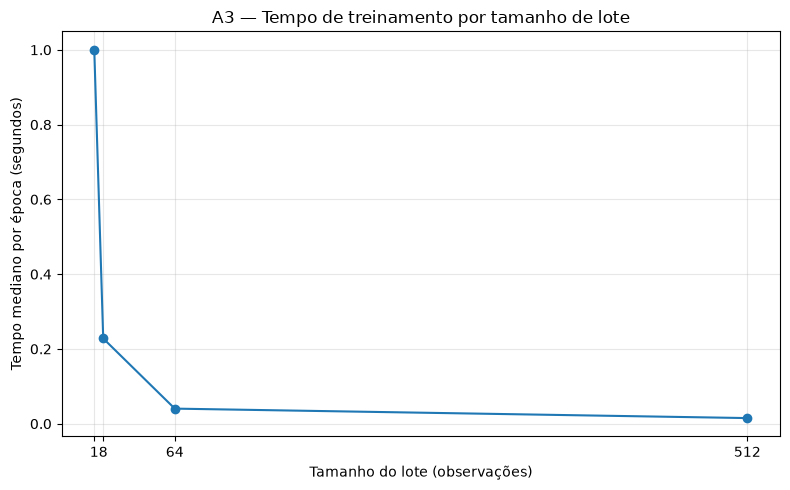


Sistema: Windows-10-10.0.26300-SP0
Dispositivo: cpu
PyTorch: 2.14.1+cpu


In [10]:
# A3 — Tempo de treinamento por tamanho de lote

import time
import copy
import platform
import matplotlib.pyplot as plt
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader

# Pasta para salvar resultados
RESULTADOS.mkdir(parents=True, exist_ok=True)

tamanhos_lote = [1, 8, 64, 512]
tempos = []

criterio = nn.BCEWithLogitsLoss()
taxa_aprendizado = 0.001

# Estado inicial comum a todas as medições
fixar_semente(SEED)
modelo_inicial = criar_modelo(11, batchnorm=False)
pesos_iniciais = copy.deepcopy(modelo_inicial.state_dict())

def executar_epoca_medida(batch_size, repeticao):
    # DataLoader com todos os exemplos de treino
    loader = DataLoader(
        ds_treino,
        batch_size=batch_size,
        shuffle=False,
        drop_last=False,
        num_workers=0
    )

    # Reinicia a rede com os mesmos pesos
    modelo = criar_modelo(11, batchnorm=False).to(DISPOSITIVO)
    modelo.load_state_dict(pesos_iniciais)

    # Novo otimizador em cada repetição
    otimizador = torch.optim.Adam(
        modelo.parameters(),
        lr=taxa_aprendizado
    )

    inicio = time.perf_counter()

    perda = treinar_epoca(
        modelo,
        loader,
        otimizador,
        criterio,
        DISPOSITIVO
    )

    fim = time.perf_counter()

    return {
        "batch_size": batch_size,
        "repeticao": repeticao,
        "segundos": fim - inicio,
        "passos": len(loader),
        "exemplos": len(loader.dataset),
        "perda": perda
    }


# Aquecimento fora da medição
loader_aquecimento = DataLoader(
    ds_treino,
    batch_size=64,
    shuffle=False,
    drop_last=False,
    num_workers=0
)

modelo_aquecimento = criar_modelo(11, batchnorm=False).to(DISPOSITIVO)
otimizador_aquecimento = torch.optim.Adam(
    modelo_aquecimento.parameters(),
    lr=taxa_aprendizado
)

_ = treinar_epoca(
    modelo_aquecimento,
    loader_aquecimento,
    otimizador_aquecimento,
    criterio,
    DISPOSITIVO
)

del modelo_aquecimento, otimizador_aquecimento


# Medições reais
for tamanho in tamanhos_lote:
    for repeticao in range(1, 4):
        resultado = executar_epoca_medida(tamanho, repeticao)
        tempos.append(resultado)

        print(
            f"Lote={tamanho:3d} | "
            f"Repetição={repeticao} | "
            f"Tempo={resultado['segundos']:.4f}s | "
            f"Passos={resultado['passos']} | "
            f"Exemplos={resultado['exemplos']}"
        )


# Tabela completa
tabela_tempos = pd.DataFrame(tempos)

# Resumo por tamanho de lote
resumo_tempos = (
    tabela_tempos
    .groupby("batch_size", as_index=False)
    .agg(
        mediana_segundos=("segundos", "median"),
        passos=("passos", "first"),
        exemplos=("exemplos", "first")
    )
)

print("\n=== RESUMO DAS MEDIÇÕES ===")
print(resumo_tempos.to_string(index=False))

# Salvar tabelas
tabela_tempos.to_csv(
    RESULTADOS / "a3_tempos_repeticoes.csv",
    index=False
)

resumo_tempos.to_csv(
    RESULTADOS / "a3_resumo_tempos.csv",
    index=False
)


# Gráfico: tempo versus tamanho do lote
plt.figure(figsize=(8, 5))

plt.plot(
    resumo_tempos["batch_size"],
    resumo_tempos["mediana_segundos"],
    marker="o"
)

plt.xticks(tamanhos_lote)
plt.xlabel("Tamanho do lote (observações)")
plt.ylabel("Tempo mediano por época (segundos)")
plt.title("A3 — Tempo de treinamento por tamanho de lote")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    RESULTADOS / "a3_tempo_por_lote.png",
    dpi=150
)

plt.show()

print("\nSistema:", platform.platform())
print("Dispositivo:", DISPOSITIVO)
print("PyTorch:", torch.__version__)


## A4. BatchNorm com último lote 1
Use um subconjunto de 65 observações do treino e lote 64, ou outra condição equivalente. Confirme o resto. Use `criar_modelo(11, batchnorm=True)`, modo de treino e `drop_last=False`. Capture especificamente o erro esperado, mostre sua mensagem e depois execute a correção que escolheu. Preserve as outras partes do notebook.

In [11]:
# A4 — Reproduzir e corrigir o erro de BatchNorm

# Subconjunto exclusivamente do treinamento
subconjunto_a4 = torch.utils.data.Subset(
    ds_treino, range(65)
)

tamanho_lote_a4 = 64

print("=== CONDIÇÃO DO EXPERIMENTO ===")
print("Observações:", len(subconjunto_a4))
print("Tamanho do lote:", tamanho_lote_a4)
print("Resto da divisão:", len(subconjunto_a4) % tamanho_lote_a4)

# Carregador que mantém o último lote incompleto
loader_erro_a4 = DataLoader(
    subconjunto_a4,
    batch_size=tamanho_lote_a4,
    shuffle=False,
    drop_last=False,
    num_workers=0
)

# Rede com BatchNorm
modelo_erro_a4 = criar_modelo(
    11, batchnorm=True
).to(DISPOSITIVO)

modelo_erro_a4.train()

criterio_a4 = nn.BCEWithLogitsLoss()
otimizador_erro_a4 = torch.optim.Adam(
    modelo_erro_a4.parameters(),
    lr=0.001
)

print("\n=== REPRODUÇÃO DO ERRO ===")

try:
    treinar_epoca(
        modelo_erro_a4,
        loader_erro_a4,
        otimizador_erro_a4,
        criterio_a4,
        DISPOSITIVO
    )

except ValueError as erro:
    if "Expected more than 1 value per channel" in str(erro):
        print("Erro esperado capturado:")
        print(type(erro).__name__ + ":", erro)
    else:
        raise


# Correção: descartar o último lote unitário
print("\n=== CORREÇÃO ===")

loader_corrigido_a4 = DataLoader(
    subconjunto_a4,
    batch_size=tamanho_lote_a4,
    shuffle=False,
    drop_last=True,
    num_workers=0
)

# Novo modelo para demonstrar a correção
modelo_corrigido_a4 = criar_modelo(
    11, batchnorm=True
).to(DISPOSITIVO)

otimizador_corrigido_a4 = torch.optim.Adam(
    modelo_corrigido_a4.parameters(),
    lr=0.001
)

perda_corrigida_a4 = treinar_epoca(
    modelo_corrigido_a4,
    loader_corrigido_a4,
    otimizador_corrigido_a4,
    criterio_a4,
    DISPOSITIVO
)

exemplos_processados_a4 = (
    len(loader_corrigido_a4) * tamanho_lote_a4
)

print("Treinamento corrigido executado com sucesso.")
print("Lotes processados:", len(loader_corrigido_a4))
print("Observações processadas:", exemplos_processados_a4)
print(
    "Observações descartadas:",
    len(subconjunto_a4) - exemplos_processados_a4
)
print("Perda do treinamento:", perda_corrigida_a4)


=== CONDIÇÃO DO EXPERIMENTO ===
Observações: 65
Tamanho do lote: 64
Resto da divisão: 1

=== REPRODUÇÃO DO ERRO ===
Erro esperado capturado:
ValueError: Expected more than 1 value per channel when training, got input size torch.Size([1, 16])

=== CORREÇÃO ===
Treinamento corrigido executado com sucesso.
Lotes processados: 1
Observações processadas: 64
Observações descartadas: 1
Perda do treinamento: 0.7391090393066406


## C. Dois mecanismos de vazamento
Selecione duas formas; pelo menos uma entre 2/4/7 e uma com dados reais. Um caminho acessível é 1 e 2, usando a base incluída. **Formas 1–7 estão descritas no enunciado.**

Trabalhe apenas com as linhas principais de treino + validação. Crie partições internas `c_...`. Não use a partição principal de teste. Defina o modelo, a métrica e as condições antes de executar o par incorreto/corrigido. Se usar a forma 7, reserve desde o início os quatro conjuntos internos e compare seleções com orçamento igual.

In [12]:
# Parte C — Preparação dos dados de desenvolvimento

from sklearn.model_selection import GroupShuffleSplit

resultados_c = []

# Combinar exclusivamente treino e validação da B2
c_desenvolvimento = pd.concat(
    [treino, validacao],
    ignore_index=True
)

# Criar divisão interna por grupos
c_divisor = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=SEED
)

c_idx_treino, c_idx_avaliacao = next(
    c_divisor.split(
        c_desenvolvimento,
        groups=c_desenvolvimento["grupo_perfil"]
    )
)

c_treino = c_desenvolvimento.iloc[c_idx_treino].copy()
c_avaliacao = c_desenvolvimento.iloc[c_idx_avaliacao].copy()

# Verificar se o teste principal permaneceu protegido
c_ids_desenvolvimento = set(c_desenvolvimento["id_linha"])
c_ids_teste = set(teste["id_linha"])

c_grupos_treino = set(c_treino["grupo_perfil"])
c_grupos_avaliacao = set(c_avaliacao["grupo_perfil"])

assert len(c_desenvolvimento) == 1279
assert c_ids_desenvolvimento.isdisjoint(c_ids_teste)
assert c_grupos_treino.isdisjoint(c_grupos_avaliacao)

assert set(c_treino["alvo"].unique()) == {0, 1}
assert set(c_avaliacao["alvo"].unique()) == {0, 1}

print("=== PREPARAÇÃO DA PARTE C ===")
print("Desenvolvimento:", len(c_desenvolvimento))
print("Treino interno:", len(c_treino))
print("Avaliação interna:", len(c_avaliacao))

print(
    "Sobreposição com teste principal:",
    len(c_ids_desenvolvimento & c_ids_teste)
)

print(
    "Perfis compartilhados internamente:",
    len(c_grupos_treino & c_grupos_avaliacao)
)

print("Classes no treino interno:", sorted(c_treino["alvo"].unique()))
print("Classes na avaliação interna:", sorted(c_avaliacao["alvo"].unique()))


=== PREPARAÇÃO DA PARTE C ===
Desenvolvimento: 1279
Treino interno: 961
Avaliação interna: 318
Sobreposição com teste principal: 0
Perfis compartilhados internamente: 0
Classes no treino interno: [np.int64(0), np.int64(1)]
Classes na avaliação interna: [np.int64(0), np.int64(1)]


In [13]:
# C1 — Vazamento por pré-processamento indevido

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import numpy as np

# Dados internos: exclusivamente desenvolvimento da Parte C
c_X_treino = c_treino[FEATURES].to_numpy()
c_y_treino = c_treino["alvo"].to_numpy()

c_X_avaliacao = c_avaliacao[FEATURES].to_numpy()
c_y_avaliacao = c_avaliacao["alvo"].to_numpy()

# PROCEDIMENTO INCORRETO
# O scaler aprende também com os dados reservados à avaliação.
c_scaler_errado = StandardScaler()

c_scaler_errado.fit(
    np.vstack([c_X_treino, c_X_avaliacao])
)

c_X_treino_errado = c_scaler_errado.transform(c_X_treino)
c_X_avaliacao_errado = c_scaler_errado.transform(c_X_avaliacao)

c_modelo_errado = LogisticRegression(
    max_iter=1000,
    random_state=SEED
)

c_modelo_errado.fit(c_X_treino_errado, c_y_treino)

c_pred_errado = c_modelo_errado.predict(c_X_avaliacao_errado)

c_acuracia_errada = accuracy_score(
    c_y_avaliacao, c_pred_errado
)


# PROCEDIMENTO CORRIGIDO
# O scaler aprende exclusivamente com o treino interno.
c_scaler_correto = StandardScaler()

c_scaler_correto.fit(c_X_treino)

c_X_treino_correto = c_scaler_correto.transform(c_X_treino)
c_X_avaliacao_correto = c_scaler_correto.transform(c_X_avaliacao)

c_modelo_correto = LogisticRegression(
    max_iter=1000,
    random_state=SEED
)

c_modelo_correto.fit(c_X_treino_correto, c_y_treino)

c_pred_correto = c_modelo_correto.predict(c_X_avaliacao_correto)

c_acuracia_correta = accuracy_score(
    c_y_avaliacao, c_pred_correto
)

# Diferença em pontos percentuais
c_diferenca = 100 * (
    c_acuracia_errada - c_acuracia_correta
)

print("=== EXPERIMENTO C1 ===")
print("Forma: 1 — Pré-processamento indevido")
print(f"Acurácia incorreta: {c_acuracia_errada:.4f}")
print(f"Acurácia corrigida: {c_acuracia_correta:.4f}")
print(f"Diferença: {c_diferenca:+.2f} pontos percentuais")

resultados_c.append({
    "forma": 1,
    "fonte": "Red Wine Quality — desenvolvimento interno",
    "metrica": "Acurácia",
    "incorreto": c_acuracia_errada,
    "corrigido": c_acuracia_correta,
    "diferenca": c_diferenca,
    "unidade": "pontos percentuais"
})


=== EXPERIMENTO C1 ===
Forma: 1 — Pré-processamento indevido
Acurácia incorreta: 0.8742
Acurácia corrigida: 0.8742
Diferença: +0.00 pontos percentuais


In [14]:
# C2 — Vazamento do alvo nas características

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
import numpy as np

# Mesmas partições internas da Parte C
c_X_treino = c_treino[FEATURES].to_numpy()
c_X_avaliacao = c_avaliacao[FEATURES].to_numpy()

c_y_treino = c_treino["alvo"].to_numpy()
c_y_avaliacao = c_avaliacao["alvo"].to_numpy()

# Padronização correta, ajustada somente no treino
c_scaler = StandardScaler()

c_X_treino_normal = c_scaler.fit_transform(c_X_treino)
c_X_avaliacao_normal = c_scaler.transform(c_X_avaliacao)


# PROCEDIMENTO CORRIGIDO
# Utiliza apenas as 11 características permitidas
c_modelo_correto2 = LogisticRegression(
    max_iter=1000,
    random_state=SEED
)

c_modelo_correto2.fit(
    c_X_treino_normal,
    c_y_treino
)

c_pred_correto2 = c_modelo_correto2.predict(
    c_X_avaliacao_normal
)

c_acuracia_correta2 = accuracy_score(
    c_y_avaliacao,
    c_pred_correto2
)


# PROCEDIMENTO INCORRETO
# Inclui explicitamente o alvo como 12ª característica
c_X_treino_vazado = np.column_stack([
    c_X_treino_normal,
    c_y_treino
])

c_X_avaliacao_vazado = np.column_stack([
    c_X_avaliacao_normal,
    c_y_avaliacao
])

c_modelo_errado2 = LogisticRegression(
    max_iter=1000,
    random_state=SEED
)

c_modelo_errado2.fit(
    c_X_treino_vazado,
    c_y_treino
)

c_pred_errado2 = c_modelo_errado2.predict(
    c_X_avaliacao_vazado
)

c_acuracia_errada2 = accuracy_score(
    c_y_avaliacao,
    c_pred_errado2
)

c_diferenca2 = 100 * (
    c_acuracia_errada2 - c_acuracia_correta2
)

print("=== EXPERIMENTO C2 ===")
print("Forma: 2 — Vazamento direto do alvo")
print(f"Acurácia incorreta: {c_acuracia_errada2:.4f}")
print(f"Acurácia corrigida: {c_acuracia_correta2:.4f}")
print(f"Diferença: {c_diferenca2:+.2f} pontos percentuais")

resultados_c.append({
    "forma": 2,
    "fonte": "Red Wine Quality — desenvolvimento interno",
    "metrica": "Acurácia",
    "incorreto": c_acuracia_errada2,
    "corrigido": c_acuracia_correta2,
    "diferenca": c_diferenca2,
    "unidade": "pontos percentuais"
})


=== EXPERIMENTO C2 ===
Forma: 2 — Vazamento direto do alvo
Acurácia incorreta: 1.0000
Acurácia corrigida: 0.8742
Diferença: +12.58 pontos percentuais


In [15]:
print(pd.DataFrame(resultados_c).to_string(index=False))
print("Total de experimentos:", len(resultados_c))

 forma                                      fonte  metrica  incorreto  corrigido  diferenca            unidade
     1 Red Wine Quality — desenvolvimento interno Acurácia   0.874214   0.874214   0.000000 pontos percentuais
     2 Red Wine Quality — desenvolvimento interno Acurácia   1.000000   0.874214  12.578616 pontos percentuais
Total de experimentos: 2


## D7. Rede principal com parada antecipada
Construa uma rede nova; não reutilize os pesos ou estatísticas do experimento incorreto da Parte C. A arquitetura de apoio pode ser usada. Complete o laço: treinar, avaliar validação, comparar melhora, copiar o melhor estado, contar paciência, parar e restaurar. Use `copy.deepcopy(modelo.state_dict())` ou tensores clonados para guardar uma cópia independente.

Não forneça o loader de teste à função de treinamento. A perda de validação seleciona a época; o teste não aparece no histórico.

Parada antecipada na época 36.

=== RESULTADOS D7 ===
Melhor época: 26
Época final: 36
Melhor perda de validação: 0.267829
Motivo: Paciência esgotada
Pesos restaurados: True


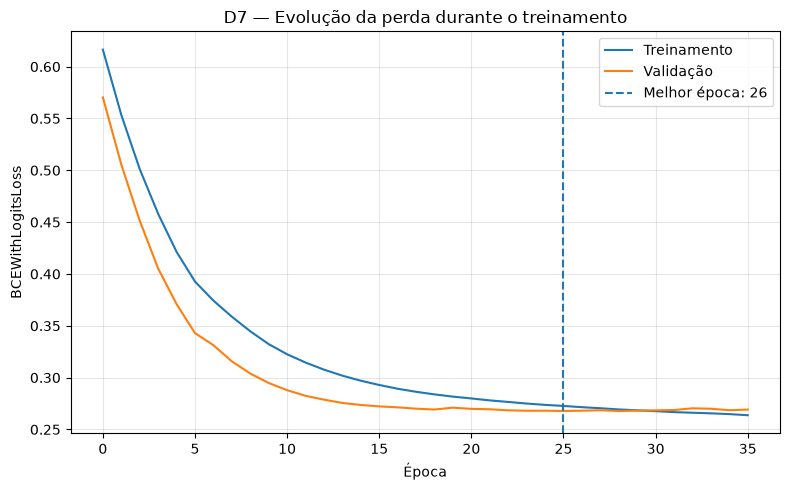

In [11]:
# D7 — Treinamento com parada antecipada

from pathlib import Path
RESULTADOS = Path("resultados")
import copy
import matplotlib.pyplot as plt
import torch
from torch import nn

def treinar_com_parada(modelo, loader_treino, loader_validacao,
                       max_epocas=100, paciencia=10, min_delta=0.0001):


    criterio = nn.BCEWithLogitsLoss()

    otimizador = torch.optim.Adam(
        modelo.parameters(),
        lr=0.001
    )

    historico = {
        "treino": [],
        "validacao": []
    }

    melhor_perda = float("inf")
    melhor_epoca = 0
    epocas_sem_melhora = 0
    melhores_pesos = None
    epoca_final = 0

    for epoca in range(1, max_epocas + 1):

        # Treinar uma época
        perda_treino = treinar_epoca(
            modelo,
            loader_treino,
            otimizador,
            criterio,
            DISPOSITIVO
        )

        # Avaliar exclusivamente na validação
        perda_validacao = avaliar_perda(
            modelo,
            loader_validacao,
            criterio,
            DISPOSITIVO
        )

        historico["treino"].append(perda_treino)
        historico["validacao"].append(perda_validacao)

        epoca_final = epoca

        # Verificar melhoria mínima
        if melhor_perda - perda_validacao > min_delta:

            melhor_perda = perda_validacao
            melhor_epoca = epoca

            # Cópia independente dos pesos
            melhores_pesos = copy.deepcopy(
                modelo.state_dict()
            )

            epocas_sem_melhora = 0

        else:
            epocas_sem_melhora += 1

        # Interromper após esgotar a paciência
        if epocas_sem_melhora >= paciencia:
            print(
                f"Parada antecipada na época {epoca}."
            )
            break

    # Restaurar o melhor estado
    modelo.load_state_dict(melhores_pesos)

    # Confirmar a restauração
    restauracao_ok = all(
        torch.equal(modelo.state_dict()[nome], valor)
        for nome, valor in melhores_pesos.items()
    )

    historico["restauracao_confirmada"] = restauracao_ok
    historico["motivo_parada"] = (
        "Paciência esgotada"
        if epocas_sem_melhora >= paciencia
        else "Máximo de épocas atingido"
    )

    return historico, melhor_epoca, epoca_final, melhor_perda


# Reprodutibilidade
fixar_semente(SEED)

# Criar o modelo principal sem BatchNorm
modelo_final = criar_modelo(
    n_entradas=11,
    batchnorm=False
).to(DISPOSITIVO)

# Executar treinamento
historico, melhor_epoca, epoca_final, melhor_perda = (
    treinar_com_parada(
        modelo_final,
        loader_treino,
        loader_validacao,
        max_epocas=100,
        paciencia=10,
        min_delta=0.0001
    )
)

print("\n=== RESULTADOS D7 ===")
print("Melhor época:", melhor_epoca)
print("Época final:", epoca_final)
print("Melhor perda de validação:", round(melhor_perda, 6))
print("Motivo:", historico["motivo_parada"])
print(
    "Pesos restaurados:",
    historico["restauracao_confirmada"]
)


# Gráfico de perda
plt.figure(figsize=(8, 5))

plt.plot(
    historico["treino"],
    label="Treinamento"
)

plt.plot(
    historico["validacao"],
    label="Validação"
)

plt.axvline(
    melhor_epoca - 1,
    linestyle="--",
    label=f"Melhor época: {melhor_epoca}"
)

plt.xlabel("Época")
plt.ylabel("BCEWithLogitsLoss")
plt.title("D7 — Evolução da perda durante o treinamento")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

RESULTADOS.mkdir(parents=True, exist_ok=True)

plt.savefig(
    RESULTADOS / "d7_curvas_perda.png",
    dpi=150
)

plt.show()


## D4. Custos como hipóteses explícitas
Descreva a ação de selecionar uma amostra como alta nota. Defina custos positivos de falso positivo e falso negativo, uma unidade e uma justificativa. Não existem custos reais no CSV. Acertos custam zero na simplificação deste laboratório.

In [13]:
# D4 — Definição dos custos de classificação

# Custos hipotéticos, expressos na mesma unidade
C_FP = 2
C_FN = 5

# Custo zero para previsões corretas
C_TN = 0
C_TP = 0

print("=== D4 — MATRIZ DE CUSTOS ===")
print("Custo do falso positivo:", C_FP)
print("Custo do falso negativo:", C_FN)
print("Custo do verdadeiro negativo:", C_TN)
print("Custo do verdadeiro positivo:", C_TP)

print("\nLimiar teórico de referência:",
      round(C_FP / (C_FP + C_FN), 4))


=== D4 — MATRIZ DE CUSTOS ===
Custo do falso positivo: 2
Custo do falso negativo: 5
Custo do verdadeiro negativo: 0
Custo do verdadeiro positivo: 0

Limiar teórico de referência: 0.2857


In [14]:
variaveis = [
    "base",
    "treino",
    "validacao",
    "teste",
    "ds_treino",
    "ds_validacao",
    "loader_treino",
    "loader_validacao",
    "C_FP",
    "C_FN"
]

for nome in variaveis:
    print(nome, ":", nome in globals())

base : True
treino : True
validacao : True
teste : True
ds_treino : True
ds_validacao : True
loader_treino : True
loader_validacao : True
C_FP : True
C_FN : True


In [15]:
print("=== VERIFICAÇÃO ANTES DA D5 ===")

print("Modelo disponível:", modelo_final is not None)
print("Pesos restaurados:", historico["restauracao_confirmada"])
print("Validação:", len(loader_validacao.dataset))
print("Custo FP:", C_FP)
print("Custo FN:", C_FN)

=== VERIFICAÇÃO ANTES DA D5 ===
Modelo disponível: True
Pesos restaurados: True
Validação: 318
Custo FP: 2
Custo FN: 5


## D5 e D6. Escolha na validação e fórmula
Use `obter_escores(modelo_final, loader_validacao, DISPOSITIVO)` após a restauração. Compare limiares usando os rótulos da validação. Inclua os casos extremos; registre regra de empate ou resolução de uma grade. Compare com 0,5 e com `C_FP/(C_FP+C_FN)`. Investigue calibração sem transformar sigmoide em garantia de probabilidade.

Salve modelo, normalização, lista de entradas, custos e limiar como escolhas fixadas antes da próxima seção.

In [16]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import confusion_matrix, brier_score_loss

limiar_escolhido = None
decisao_congelada = False

# Verificar se o treinamento D7 está disponível
if (
    "modelo_final" not in globals()
    or modelo_final is None
    or "historico" not in globals()
    or historico is None
    or not historico.get("restauracao_confirmada", False)
):
    raise RuntimeError(
        "Execute a D7 e restaure os melhores pesos antes da D5."
    )

# Custos definidos previamente na D4
assert C_FP > 0 and C_FN > 0

# Obter rótulos e escores APENAS da validação
y_val, escores_val = obter_escores(
    modelo_final, loader_validacao, DISPOSITIVO
)

assert len(y_val) == len(ds_validacao)
assert np.isfinite(escores_val).all()

# Calcular custo para um determinado limiar
def calcular_custo(y_real, escores, limiar):
    previsoes = (escores >= limiar).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_real, previsoes, labels=[0, 1]
    ).ravel()

    custo_total = C_FP * fp + C_FN * fn
    custo_medio = custo_total / len(y_real)

    return {
        "limiar": float(limiar),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
        "TN": int(tn),
        "custo_total": float(custo_total),
        "custo_medio": float(custo_medio)
    }


# Buscar os escores únicos, incluindo extremos
# 0 representa todas as previsões positivas
# Acima do maior escore representa todas negativas
candidatos = np.unique(
    np.concatenate([
        [0.0],
        escores_val,
        [np.nextafter(float(escores_val.max()), np.inf)]
    ])
)

resultados_limiares = [
    calcular_custo(y_val, escores_val, limiar)
    for limiar in candidatos
]

tabela_limiares = pd.DataFrame(resultados_limiares)

# Critério de desempate:
# menor custo; em caso de empate, maior limiar
melhor_resultado = (
    tabela_limiares
    .sort_values(
        ["custo_total", "limiar"],
        ascending=[True, False]
    )
    .iloc[0]
)

limiar_escolhido = float(melhor_resultado["limiar"])

resultado_padrao = calcular_custo(
    y_val, escores_val, 0.5
)

resultado_escolhido = calcular_custo(
    y_val, escores_val, limiar_escolhido
)

print("=== D5 — BUSCA NA VALIDAÇÃO ===")
print("Observações avaliadas:", len(y_val))
print("Candidatos avaliados:", len(candidatos))
print("Regra de desempate: maior limiar")
print(f"Limiar escolhido: {limiar_escolhido:.6f}")

print("\nLimiar padrão (0,5):")
print(resultado_padrao)

print("\nLimiar escolhido:")
print(resultado_escolhido)

print(
    "\nRedução do custo total:",
    resultado_padrao["custo_total"]
    - resultado_escolhido["custo_total"]
)

# D6 — Comparar com o limiar teórico
limiar_teorico = C_FP / (C_FP + C_FN)

resultado_teorico = calcular_custo(
    y_val, escores_val, limiar_teorico
)

brier_validacao = brier_score_loss(
    y_val, escores_val
)

print("\n=== D6 — COMPARAÇÃO TEÓRICA ===")
print(f"Limiar teórico: {limiar_teorico:.6f}")
print(f"Limiar empírico: {limiar_escolhido:.6f}")
print(
    "Diferença empírico - teórico:",
    round(limiar_escolhido - limiar_teorico, 6)
)
print("Custo no limiar teórico:", resultado_teorico["custo_total"])
print("Brier score na validação:", round(brier_validacao, 6))
print(
    "O Brier score auxilia a análise, mas não comprova "
    "calibração perfeita."
)

# Salvar tabela completa de candidatos
pasta_resultados = Path("resultados")
pasta_resultados.mkdir(exist_ok=True)

tabela_limiares.to_csv(
    pasta_resultados / "d5_busca_limiares.csv",
    index=False
)

# Congelar as decisões antes da avaliação final
configuracao_congelada = {
    "features": tuple(FEATURES),
    "media": ds_treino.media.copy(),
    "desvio": ds_treino.desvio.copy(),
    "melhor_epoca": melhor_epoca,
    "limiar": limiar_escolhido,
    "C_FP": C_FP,
    "C_FN": C_FN
}

decisao_congelada = True

print("\nDecisão congelada:", decisao_congelada)
print("Teste principal não foi consultado.")


=== D5 — BUSCA NA VALIDAÇÃO ===
Observações avaliadas: 318
Candidatos avaliados: 274
Regra de desempate: maior limiar
Limiar escolhido: 0.276928

Limiar padrão (0,5):
{'limiar': 0.5, 'FP': 11, 'FN': 28, 'TP': 5, 'TN': 274, 'custo_total': 162.0, 'custo_medio': 0.5094339622641509}

Limiar escolhido:
{'limiar': 0.27692779898643494, 'FP': 32, 'FN': 10, 'TP': 23, 'TN': 253, 'custo_total': 114.0, 'custo_medio': 0.3584905660377358}

Redução do custo total: 48.0

=== D6 — COMPARAÇÃO TEÓRICA ===
Limiar teórico: 0.285714
Limiar empírico: 0.276928
Diferença empírico - teórico: -0.008786
Custo no limiar teórico: 119.0
Brier score na validação: 0.079785
O Brier score auxilia a análise, mas não comprova calibração perfeita.

Decisão congelada: True
Teste principal não foi consultado.


## D1, D2 e D3. Avaliação final
Só agora obtenha escores no teste com o modelo restaurado e decisão congelada. Avalie as duas regras já fixadas (0,5 e limiar escolhido). O baseline usa a classe majoritária **do treino**. Produza matriz com ordem `[0, 1]`, métricas, prevalência e custos.

AUC-ROC e AUC-PR usam escores. Com `precision_recall_curve`, calcule a área trapezoidal usando `auc(recall, precision)`; se reportar `average_precision_score`, chame-a AP. Na ROC, desenhe a diagonal aleatória. Na PR, desenhe a prevalência do teste.

Não use o resultado do teste para voltar à busca. Relate os limites observados.

=== D1/D2 — AVALIAÇÃO FINAL ===
Observações de teste: 320
Positivos no teste: 45
Prevalência positiva: 14.0625%
Classe majoritária no treino: 0

=== TABELA FINAL ===
                  regra  limiar  acuracia  precisao  revocacao     F1  AUC_ROC  AUC_PR  custo_total  custo_medio  TN  FP  FN  TP
      Trivial do treino     NaN    0.8594    0.0000     0.0000 0.0000      NaN     NaN          225       0.7031 275   0  45   0
      Rede - limiar 0.5  0.5000    0.8750    0.6190     0.2889 0.3939   0.8816  0.5562          176       0.5500 267   8  32  13
Rede - limiar escolhido  0.2769    0.8438    0.4576     0.6000 0.5192   0.8816  0.5562          154       0.4812 243  32  18  27

=== MATRIZ — LIMIAR 0.5 ===
Linhas: reais 0,1 | Colunas: previstas 0,1
[[267   8]
 [ 32  13]]

=== MATRIZ — LIMIAR ESCOLHIDO ===
Linhas: reais 0,1 | Colunas: previstas 0,1
[[243  32]
 [ 18  27]]


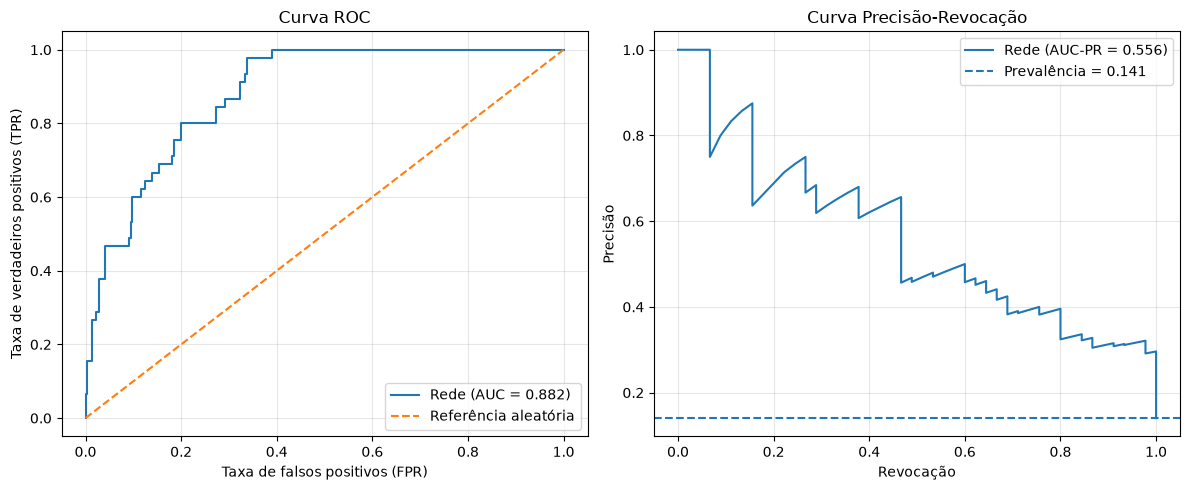


Resultados salvos em: C:\Users\Arnóbio\Downloads\classroom-lab-02 (1)\classroom-lab-02\resultados
Avaliação final concluída.


In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    auc
)

# Confirmar que todas as decisões foram fixadas
if not decisao_congelada:
    raise RuntimeError(
        "Conclua D5/D6 antes de avaliar o teste."
    )

assert historico["restauracao_confirmada"]
assert np.isclose(
    limiar_escolhido,
    configuracao_congelada["limiar"]
)
assert C_FP == configuracao_congelada["C_FP"]
assert C_FN == configuracao_congelada["C_FN"]
assert tuple(FEATURES) == configuracao_congelada["features"]
assert np.array_equal(
    ds_teste.media,
    configuracao_congelada["media"]
)
assert np.array_equal(
    ds_teste.desvio,
    configuracao_congelada["desvio"]
)

RESULTADOS = Path("resultados")
RESULTADOS.mkdir(parents=True, exist_ok=True)

# Gerar os escores do teste uma única vez
y_teste, escores_teste = obter_escores(
    modelo_final,
    loader_teste,
    DISPOSITIVO
)

assert len(y_teste) == len(ds_teste)
assert len(escores_teste) == len(y_teste)
assert np.isfinite(escores_teste).all()

prevalencia_teste = np.mean(y_teste)

# Classe majoritária identificada apenas no treino
classe_majoritaria = int(
    treino["alvo"].value_counts().idxmax()
)

previsoes_triviais = np.full(
    len(y_teste),
    classe_majoritaria,
    dtype=int
)


def avaliar_regra(nome, previsoes, limiar=None,
                  escores=None):

    tn, fp, fn, tp = confusion_matrix(
        y_teste, previsoes, labels=[0, 1]
    ).ravel()

    custo_total = C_FP * fp + C_FN * fn

    resultado = {
        "regra": nome,
        "limiar": limiar,
        "acuracia": accuracy_score(
            y_teste, previsoes
        ),
        "precisao": precision_score(
            y_teste, previsoes,
            zero_division=0
        ),
        "revocacao": recall_score(
            y_teste, previsoes,
            zero_division=0
        ),
        "F1": f1_score(
            y_teste, previsoes,
            zero_division=0
        ),
        "AUC_ROC": np.nan,
        "AUC_PR": np.nan,
        "custo_total": custo_total,
        "custo_medio": custo_total / len(y_teste),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    }

    if escores is not None:
        resultado["AUC_ROC"] = roc_auc_score(
            y_teste, escores
        )

        precisao_curva, revocacao_curva, _ = (
            precision_recall_curve(
                y_teste, escores
            )
        )

        resultado["AUC_PR"] = auc(
            revocacao_curva,
            precisao_curva
        )

    return resultado


# Regras previamente definidas
previsoes_padrao = (
    escores_teste >= 0.5
).astype(int)

previsoes_escolhidas = (
    escores_teste >= limiar_escolhido
).astype(int)


# Tabela final de métricas
avaliacao_final = pd.DataFrame([
    avaliar_regra(
        "Trivial do treino",
        previsoes_triviais
    ),
    avaliar_regra(
        "Rede - limiar 0.5",
        previsoes_padrao,
        limiar=0.5,
        escores=escores_teste
    ),
    avaliar_regra(
        "Rede - limiar escolhido",
        previsoes_escolhidas,
        limiar=limiar_escolhido,
        escores=escores_teste
    )
])

print("=== D1/D2 — AVALIAÇÃO FINAL ===")
print("Observações de teste:", len(y_teste))
print("Positivos no teste:", int(y_teste.sum()))
print(
    f"Prevalência positiva: {prevalencia_teste:.4%}"
)
print("Classe majoritária no treino:",
      classe_majoritaria)

print("\n=== TABELA FINAL ===")
print(
    avaliacao_final.round(4).to_string(
        index=False
    )
)

# Matrizes de confusão
matriz_padrao = confusion_matrix(
    y_teste,
    previsoes_padrao,
    labels=[0, 1]
)

matriz_escolhida = confusion_matrix(
    y_teste,
    previsoes_escolhidas,
    labels=[0, 1]
)

print("\n=== MATRIZ — LIMIAR 0.5 ===")
print("Linhas: reais 0,1 | Colunas: previstas 0,1")
print(matriz_padrao)

print("\n=== MATRIZ — LIMIAR ESCOLHIDO ===")
print("Linhas: reais 0,1 | Colunas: previstas 0,1")
print(matriz_escolhida)


# D3 — Curvas ROC e Precisão-Revocação
fpr, tpr, _ = roc_curve(
    y_teste, escores_teste
)

precisao_curva, revocacao_curva, _ = (
    precision_recall_curve(
        y_teste, escores_teste
    )
)

area_roc = roc_auc_score(
    y_teste, escores_teste
)

area_pr = auc(
    revocacao_curva,
    precisao_curva
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Curva ROC
axes[0].plot(
    fpr, tpr,
    label=f"Rede (AUC = {area_roc:.3f})"
)
axes[0].plot(
    [0, 1], [0, 1],
    "--", label="Referência aleatória"
)
axes[0].set_xlabel(
    "Taxa de falsos positivos (FPR)"
)
axes[0].set_ylabel(
    "Taxa de verdadeiros positivos (TPR)"
)
axes[0].set_title("Curva ROC")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Curva Precisão-Revocação
axes[1].plot(
    revocacao_curva,
    precisao_curva,
    label=f"Rede (AUC-PR = {area_pr:.3f})"
)
axes[1].axhline(
    prevalencia_teste,
    linestyle="--",
    label=f"Prevalência = {prevalencia_teste:.3f}"
)
axes[1].set_xlabel("Revocação")
axes[1].set_ylabel("Precisão")
axes[1].set_title("Curva Precisão-Revocação")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    RESULTADOS / "d3_curvas_roc_pr.png",
    dpi=150
)

plt.show()

# Salvar os resultados
avaliacao_final.to_csv(
    RESULTADOS / "d1_d2_metricas_finais.csv",
    index=False
)

pd.DataFrame(
    matriz_padrao,
    index=["Real 0", "Real 1"],
    columns=["Previsto 0", "Previsto 1"]
).to_csv(
    RESULTADOS / "d2_matriz_padrao.csv"
)

pd.DataFrame(
    matriz_escolhida,
    index=["Real 0", "Real 1"],
    columns=["Previsto 0", "Previsto 1"]
).to_csv(
    RESULTADOS / "d2_matriz_escolhida.csv"
)

print("\nResultados salvos em:", RESULTADOS.resolve())
print("Avaliação final concluída.")


## D8. Recomendação final
Escreva no README o parágrafo para quem decide: ação, limiar, evidência final, custos hipotéticos, riscos e limitações. Cite o conjunto avaliado. Não reivindique desempenho em novos produtores, regiões ou datas não observados.

## Conferência da entrega
Reinicie o kernel e execute tudo. O notebook preenchido deve mostrar as saídas de todas as partes; pendências não são resultados. Preencha o README e o arquivo obrigatório de uso de IA. Inclua as referências e registre alterações no apoio.

In [ ]:
pendencias = []
for nome, valor in [('particoes', particoes), ('ds_treino', ds_treino),
    ('loader_treino', loader_treino), ('historico', historico),
    ('limiar_escolhido', limiar_escolhido), ('avaliacao_final', avaliacao_final)]:
    if valor is None:
        pendencias.append(nome)
if not tempos: pendencias.append('tempos A3')
if len(resultados_c) < 2: pendencias.append('dois resultados C')
print('Pendências estruturais:', pendencias)
print('Esta checagem não corrige a análise nem substitui o checklist do enunciado.')